# Student Depression prediction.

> This is the dataset: https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset
1. Problem Definition
    - We have a large set of data that includes various student features and also corrosponding labels regarding if a student is depressed or not.
    - Our main task is to build a machine learning model that can take students records as an input and predict wheather a student is depressed or not.
    - From the problem definition we can say that this is a binary classification problem. Maybe we will pick some models regarding our problem definition.
       
2. Getting our data ready
    - We will first try to get our data ready. Most importently we will check if all the values are given or not. If there are null values given then we will take action accordingly.
      
3. Features
    - This is the detailed feature dictionary:
    - Gender: The gender of the respondent (e.g., Male/Female).
    - Age: The age of the student in years (ranges from 17 to 28).
    - Family_background: The economic or class status of the family (e.g., Middle class).
    - Relationship_status: The romantic relationship status of the student (e.g., Single, Complicated, In a Relationship).
    - Marital_status: The marital status of the student (e.g., Unmarried).
    - Living_style: The current living arrangement (e.g., Bachelor (living alone/with peers), Family).
    - Current_semester: The semester the student is currently enrolled in.
    - CGPA: Cumulative Grade Point Average (academic performance).
    - friend_circle: Indicates whether the respondent has an active friend circle (Yes/No).
    - Health_condition: General physical health condition (e.g., Good, Normal, Abnormal, Critical).
    - Cost_without_study: Estimated living expenses/costs outside of formal educational fees.
    - Home_division: The home region/division of the respondent (e.g., Dhaka, Chittagong).
    - Depression (Target Variable): Indicates whether the respondent is experiencing depression (Yes/No).
4. Selecting models and tuning the hyper perameters

5. Evaluating our model

6. Saving our model




In [2]:
# Organizing our workflow:
# Importing some basic packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importing our models
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# importing modeling tools
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

# Evaluation tools
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [3]:
data = pd.read_csv("Student_Depression_Dataset.csv")
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [4]:
# Now check the complition of values
data.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

In [7]:
data.shape, data.size

((4464, 13), 58032)

In [8]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 453.5 KB


In [17]:
# As the value of label is string, we have to convert the yes = 1, and no = 0
data["Depression"] = data["Depression"].str.lower().replace({"yes":1, "no":0})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,1


In [18]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(1), str(8)
memory usage: 453.5+ KB


In [19]:
data["Depression"].value_counts()

Depression
0    3263
1    1201
Name: count, dtype: int64

In [20]:
# Now we have to convert the friend circle to 0 and 1 as those are also yes/no values 
data["friend_circle"] = data["friend_circle"].str.lower().replace({"yes":1, "no":0})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,0,Good,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,0,Abnormal,16693,Dhaka,1


In [22]:
data["Marital_status"].value_counts()

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

In [24]:
data["Health_condition"].value_counts()

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

In [25]:
data.Gender.value_counts()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

In [27]:
data.Gender = data.Gender.str.lower().replace({"female": 0, "male": 1})
data.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0,22,Middle class,Single,Unmarried,Bachelor,8,3.43,1,Critical,10113,Chittagong,1
1,1,19,Middle class,Single,Unmarried,Bachelor,2,3.70,1,Abnormal,13815,Chittagong,1
2,1,23,Middle class,Single,Unmarried,Family,8,3.28,0,Abnormal,15450,Dhaka,1
3,1,20,Middle class,Complicated,Unmarried,Family,2,3.77,0,Good,17413,Dhaka,0
4,0,21,Middle class,Single,Unmarried,Family,1,4.00,0,Abnormal,16693,Dhaka,1


## Exploratory data analysis (EDA):

In [28]:
# Now let's try to find a relation between sex and depression rate
pd.crosstab(data["Gender"], data["Depression"])

Depression,0,1
Gender,,
0,1807,655
1,1456,546


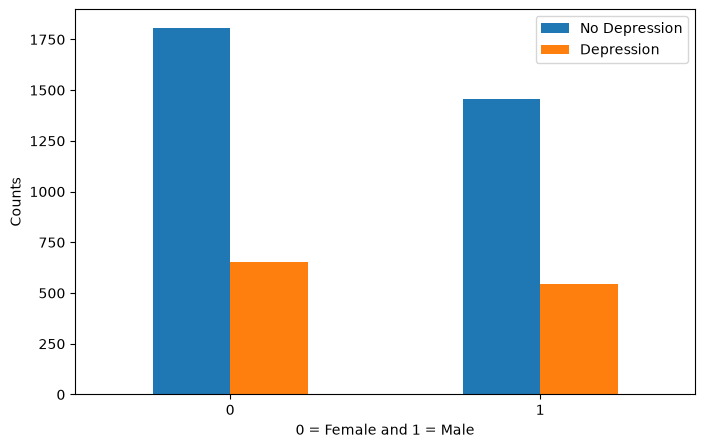

In [34]:
# Now let's plot this in a graph
pd.crosstab(data["Gender"], data["Depression"]).plot(kind="bar", figsize=(8,5))
plt.xlabel("0 = Female and 1 = Male")
plt.xticks(rotation=0)
plt.ylabel("Counts")
plt.legend(["No Depression", "Depression"])
plt.show()

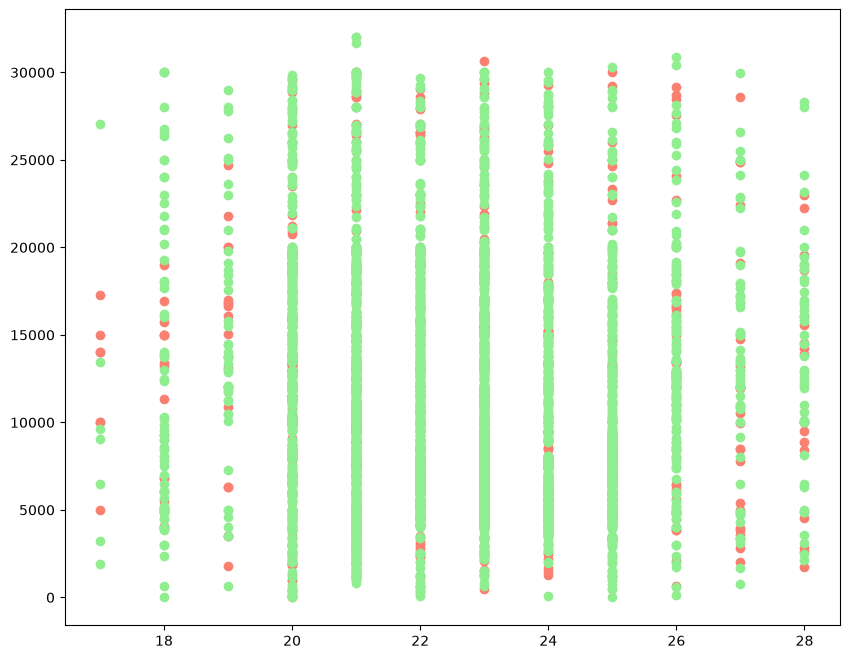

In [39]:
# Now let's compare the marital status of the gender and their depression rate
fig = plt.figure(figsize=(10,8))

# First lets check the male scatter
plt.scatter(data.Age[data.Depression == 1],
           data.Cost_without_study[data.Depression == 1],
           c=["salmon"])
plt.scatter(data.Age[data.Depression==0],
           data.Cost_without_study[data.Depression==0],
           c=["lightgreen"])

plt.show()

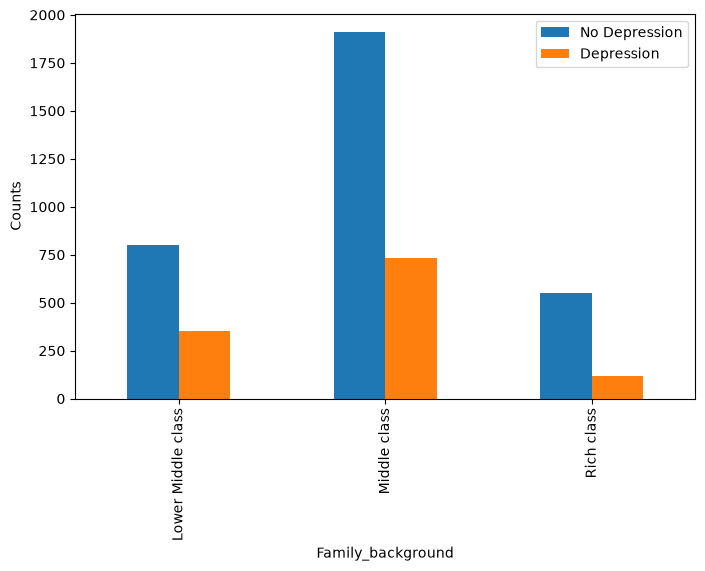

In [41]:
pd.crosstab(data["Family_background"], data["Depression"]).plot.bar(figsize=(8,5))
plt.xlabel("Family_background")
plt.ylabel("Counts")
plt.legend(["No Depression", "Depression"])
plt.show()